# Deuxième partie — Exercice 2 : mini-GPT par caractères

Un Transformer autorégressif entraîné **depuis zéro** sur le fichier original
`corpus.txt` fourni avec les exercices. Il prédit le prochain caractère sur toutes
les positions, puis génère 200 caractères à trois températures.
Ce petit corpus pédagogique favorise les répétitions ; la qualité d'un grand GPT
préentraîné n'est pas attendue.

In [1]:
from copy import deepcopy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)
# Deux threads suffisent pour ces petits modèles et limitent le surcoût CPU.
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RACINE = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()),
    None,
)
if RACINE is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dépôt Architecture-Transformer.")
print("Périphérique :", device)

CORPUS = RACINE / "notebooks" / "exercises" / "corpus.txt"
LONGUEUR = 64
BATCH_SIZE = 32
ETAPES = 800
texte = CORPUS.read_text(encoding="utf-8")
caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)
frontiere = int(0.9 * len(tokens))
train_tokens, val_tokens = tokens[:frontiere], tokens[frontiere:]
assert min(len(train_tokens), len(val_tokens)) > LONGUEUR
print(f"{len(texte):,} caractères ; vocabulaire de {len(stoi)} caractères")
print(f"Découpage contigu : {len(train_tokens)} train / {len(val_tokens)} validation")
print("Entrée :", repr(texte[:20]))
print("Cible  :", repr(texte[1:21]))

Périphérique : cpu
7,210 caractères ; vocabulaire de 50 caractères
Découpage contigu : 6489 train / 721 validation
Entrée : 'Le matin, la ville s'
Cible  : 'e matin, la ville se'


## 1. Fenêtres et cibles décalées

Aucune fenêtre ne traverse la frontière entre entraînement et validation. Les
positions de départ sont tirées aléatoirement dans chaque partie. Le vocabulaire
des caractères décrit le corpus ; les poids sont appris uniquement sur sa partie train.

In [2]:
def batch(donnees, generateur):
    debuts = torch.randint(len(donnees) - LONGUEUR, (BATCH_SIZE,), generator=generateur)
    indices = debuts.tolist()
    x = torch.stack([donnees[i:i + LONGUEUR] for i in indices])
    y = torch.stack([donnees[i + 1:i + LONGUEUR + 1] for i in indices])
    assert torch.equal(x[:, 1:], y[:, :-1])
    return x.to(device), y.to(device)

generateur_train = torch.Generator().manual_seed(42)
xb, yb = batch(train_tokens, generateur_train)
assert xb.shape == yb.shape == (BATCH_SIZE, 64)
print("Formes entrée et cible :", tuple(xb.shape), tuple(yb.shape))

Formes entrée et cible : (32, 64) (32, 64)


## 2. Deux blocs GPT avec normalisation avant l'attention

Chaque bloc applique `LayerNorm → attention causale → résidu`, puis
`LayerNorm → MLP 64 → 256 → 64 avec GELU → résidu`. Les quatre têtes ne peuvent
lire aucune position future. Avec
[MultiheadAttention](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html),
une valeur booléenne `True` dans `attn_mask` interdit la relation correspondante.

In [3]:
class BlocGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm1 = nn.LayerNorm(64)
        self.attention = nn.MultiheadAttention(64, 4, dropout=0.1, batch_first=True)
        self.norm2 = nn.LayerNorm(64)
        self.mlp = nn.Sequential(
            nn.Linear(64, 256), nn.GELU(), nn.Linear(256, 64), nn.Dropout(0.1)
        )
        self.dropout = nn.Dropout(0.1)
        self.register_buffer("masque", torch.triu(
            torch.ones(LONGUEUR, LONGUEUR, dtype=torch.bool), diagonal=1
        ), persistent=False)

    def forward(self, x):
        z = self.norm1(x)
        attention, _ = self.attention(
            z, z, z, attn_mask=self.masque[:x.size(1), :x.size(1)], need_weights=False
        )
        x = x + self.dropout(attention)
        return x + self.mlp(self.norm2(x))

class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire):
        super().__init__()
        self.tokens = nn.Embedding(taille_vocabulaire, 64)
        self.positions = nn.Embedding(LONGUEUR, 64)
        self.blocs = nn.Sequential(BlocGPT(), BlocGPT())
        self.norm = nn.LayerNorm(64)
        self.sortie = nn.Linear(64, taille_vocabulaire)

    def forward(self, ids):
        assert 0 < ids.size(1) <= LONGUEUR
        positions = torch.arange(ids.size(1), device=ids.device)
        x = self.tokens(ids) + self.positions(positions).unsqueeze(0)
        return self.sortie(self.norm(self.blocs(x)))

    @torch.no_grad()
    def generer(self, ids, nombre=200, temperature=1.0, generateur=None):
        if temperature <= 0 or ids.size(1) == 0:
            raise ValueError("La température et la longueur de l'amorce doivent être positives.")
        self.eval()
        for _ in range(nombre):
            logits = self(ids[:, -LONGUEUR:])[:, -1, :] / temperature
            suivant = torch.multinomial(logits.softmax(dim=-1), 1, generator=generateur)
            ids = torch.cat((ids, suivant), dim=1)
        return ids

modele = MiniGPT(len(stoi)).to(device)
assert modele(xb).shape == (BATCH_SIZE, 64, len(stoi))
print(f"{sum(p.numel() for p in modele.parameters()):,} paramètres")

110,642 paramètres


## 3. Vérification du masque causal

En mode `eval()`, changer la seconde moitié d'une séquence doit laisser les logits
de la première moitié inchangés. Ce test échouerait si le réseau lisait le futur.

In [4]:
def verifier_causalite(modele):
    modele.eval()
    original = train_tokens[:LONGUEUR].unsqueeze(0).to(device)
    modifie = original.clone()
    modifie[:, 32:] = (modifie[:, 32:] + 1) % len(stoi)
    with torch.no_grad():
        logits_originaux = modele(original)
        logits_modifies = modele(modifie)
    torch.testing.assert_close(logits_originaux[:, :32], logits_modifies[:, :32], rtol=1e-5, atol=1e-6)
    print("Causalité vérifiée : changer le futur ne modifie pas les logits du passé.")

verifier_causalite(modele)

Causalité vérifiée : changer le futur ne modifie pas les logits du passé.


## 4. Entraînement par entropie croisée

La perte utilise toutes les positions. La validation utilise les mêmes huit batches
à chaque mesure pour comparer les étapes sans bruit d'échantillonnage supplémentaire.
On restaure les poids ayant la plus faible perte de validation.

Avant entraînement | validation=4.0177


Étape 100 | train=3.1052 | validation=2.7225


Étape 200 | train=2.5823 | validation=2.4997


Étape 300 | train=2.4132 | validation=2.4065


Étape 400 | train=2.3332 | validation=2.3480


Étape 500 | train=2.2832 | validation=2.3098


Étape 600 | train=2.2380 | validation=2.2636


Étape 700 | train=2.2009 | validation=2.2335


Étape 800 | train=2.1679 | validation=2.2160


Causalité vérifiée : changer le futur ne modifie pas les logits du passé.


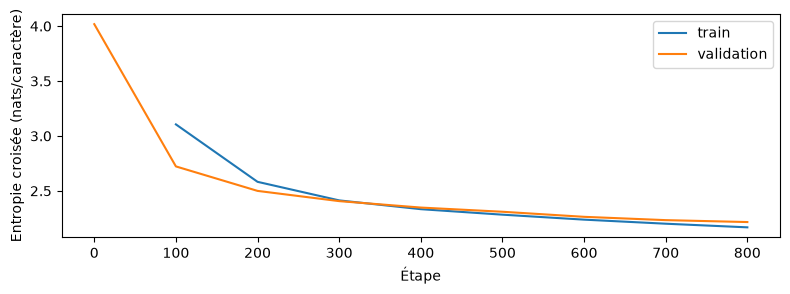

In [5]:
optimiseur = torch.optim.AdamW(modele.parameters(), lr=3e-4)

def perte_prediction(logits, cibles):
    return F.cross_entropy(logits.reshape(-1, len(stoi)), cibles.reshape(-1))

@torch.no_grad()
def evaluer_validation():
    modele.eval()
    generateur = torch.Generator().manual_seed(123)
    pertes = []
    for _ in range(8):
        vx, vy = batch(val_tokens, generateur)
        pertes.append(perte_prediction(modele(vx), vy).item())
    return float(np.mean(pertes))

historique = []
meilleure_perte = evaluer_validation()
meilleurs_poids = deepcopy(modele.state_dict())
historique.append((0, float("nan"), meilleure_perte))
print(f"Avant entraînement | validation={meilleure_perte:.4f}", flush=True)
pertes_train = []
for etape in range(1, ETAPES + 1):
    modele.train()
    xb, yb = batch(train_tokens, generateur_train)
    optimiseur.zero_grad(set_to_none=True)
    logits = modele(xb)
    perte = perte_prediction(logits, yb)
    assert torch.isfinite(perte)
    perte.backward()
    nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
    optimiseur.step()
    pertes_train.append(perte.item())
    if etape % 100 == 0:
        val_loss = evaluer_validation()
        train_loss = float(np.mean(pertes_train))
        historique.append((etape, train_loss, val_loss))
        print(f"Étape {etape:3d} | train={train_loss:.4f} | validation={val_loss:.4f}", flush=True)
        pertes_train = []
        if val_loss < meilleure_perte:
            meilleure_perte = val_loss
            meilleurs_poids = deepcopy(modele.state_dict())
modele.load_state_dict(meilleurs_poids)
modele.eval()
verifier_causalite(modele)
plt.figure(figsize=(8, 3))
etapes, courbe_train, courbe_validation = zip(*historique)
plt.plot(etapes, courbe_train, label="train")
plt.plot(etapes, courbe_validation, label="validation")
plt.xlabel("Étape")
plt.ylabel("Entropie croisée (nats/caractère)")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Générer exactement 200 caractères à chaque température

L'amorce et la graine d'échantillonnage restent les mêmes pour comparer les températures.
À chaque étape, le modèle reçoit au plus les 64 derniers caractères.

In [6]:
amorce = "Le "
ids = torch.tensor([[stoi[c] for c in amorce]], dtype=torch.long, device=device)
generations = {}
for temperature in (0.5, 1.0, 1.5):
    generateur = torch.Generator(device=device).manual_seed(2026)
    sortie = modele.generer(ids.clone(), nombre=200, temperature=temperature, generateur=generateur)
    resultat = "".join(itos[i] for i in sortie[0].tolist())
    assert len(resultat) == len(amorce) + 200
    generations[temperature] = resultat
    print(f"\nTempérature {temperature} — 200 nouveaux caractères :\n{resultat}")


Température 0.5 — 200 nouveaux caractères :
Le le dhatre son dentrau con pre sériontit s prore pe lis contile moiteren tre dis ple lage s mente le de dengiondent iles podes des diont panntifion ure pantititie pen plie isetation de ar iounte le de 



Température 1.0 — 200 nouveaux caractères :
Le lr lhitsêtiodiheu rau miée me. Le ane ces le.



Aon s cone le moiteran tréde ataiodorévaiambonsît le magans du ct iles psteuionsontententénul. Le éat va s al'e deundes e isetabont se a diounte t s so



Température 1.5 — 200 nouveaux caractères :
Le lrylhijorhiddiheu rautsiée me.jérionure fférores era s con. Utemoiteranétre. jataiodoagioiambnnsît le mçgans rduxtoiles psteuionsobixvampavéul. à Unat va aral'lexMun plieeisetabrrez eramaisuithes. rér


## 6. Réponses aux questions

**Observation des sorties enregistr?es :** les trois textes restent peu coh?rents. ? basse temp?rature, les fragments fr?quents et les r?p?titions dominent ; ? haute temp?rature, davantage de combinaisons inhabituelles apparaissent. Ce corpus et cet entra?nement courts ne suffisent pas ? produire un texte fran?ais fluide.

1. **Sans masque causal :** à l'entraînement, une position pourrait lire le caractère
   suivant, qui est précisément sa cible. La perte deviendrait artificiellement facile
   à réduire, sans apprendre correctement la génération où ce futur est indisponible.
2. **Température :** `softmax(logits / T)` concentre les probabilités lorsque `T=0.5`
   et tend à produire des suites plus prévisibles, parfois répétitives. `T=1.0` garde
   la distribution apprise. `T=1.5` l'aplatit et favorise la diversité, avec davantage
   d'erreurs possibles. Les trois sorties ci-dessus permettent une comparaison concrète ;
   le résultat dépend aussi de la graine et de la petite taille du corpus.
3. **Cibles décalées :** chaque position doit prédire le caractère qui la suit. Sans
   décalage, le modèle apprendrait principalement à recopier son entrée, ce qui ne
   correspond pas à la tâche autorégressive.